In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
#        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
from pathlib import Path
import gc
import json
import math
import random
import time
import warnings

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from IPython.display import display

SEED = 42
BACKBONES = ["densenet121", "resnet50", "efficientnet_b0"]
LABELS = ["Effusion", "Cardiomegaly", "Pneumothorax", "Atelectasis",
          "Consolidation", "Mass", "Nodule"]

IMAGE_SIZE = 224
NUM_WORKERS = 2
EVAL_BATCH_SIZE = 64
MIN_POS = 10

# Follow the supplied tuning notebook's final-retraining sample sizes.
FINAL_TRAIN_SIZE = 40_000
FINAL_VAL_SIZE = 8_000
TRAIN_DIAGNOSTIC_SIZE = 2_000
FINAL_EPOCHS = 8

# Stability settings retained from the tuning notebook.
WARMUP_FRAC = 0.05
GRAD_CLIP_NORM = 1.0
USE_IMAGENET_WEIGHTS = False

PREPROCESSED_ROOT = Path("/kaggle/input/notebooks/t1f3001843/dsai-nih-preprocessing")
# Point this at the tuning notebook output folder (or attached Kaggle dataset).
TUNING_RESULTS_ROOT = Path("/kaggle/input/notebooks/t1f3001843/dsai-nih-hyperparameter/nih_multi_backbone_tuning")
OUTPUT_DIR = Path("/kaggle/working/nih_generalization_experiments")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Optional fallback. Populate only if best_config.json files cannot be loaded.
# Values must come from your completed NIH hyperparameter tuning results.
MANUAL_BEST_CONFIGS = {
    # "densenet121": {"learning_rate": ..., "batch_size": ..., "dropout": ..., "weight_decay": ...},
    # "resnet50": {"learning_rate": ..., "batch_size": ..., "dropout": ..., "weight_decay": ...},
    # "efficientnet_b0": {"learning_rate": ..., "batch_size": ..., "dropout": ..., "weight_decay": ...},
}

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

Device: cuda
GPU: Tesla T4


In [3]:
manifest_path = PREPROCESSED_ROOT / "outputs/processed/nih_full_manifest.csv"
if not manifest_path.exists():
    candidates = list(PREPROCESSED_ROOT.rglob("nih_full_manifest.csv"))
    if not candidates:
        raise FileNotFoundError(f"Could not find nih_full_manifest.csv under {PREPROCESSED_ROOT}")
    manifest_path = candidates[0]

print("Manifest:", manifest_path)
manifest = pd.read_csv(manifest_path)

required_columns = {"official_split", "patient_id", "shard_index", "shard_path", *LABELS}
missing_columns = required_columns - set(manifest.columns)
if missing_columns:
    raise ValueError(f"Manifest is missing columns: {sorted(missing_columns)}")

# Resolve shard paths using the same relative-path strategy as the supplied notebook.
shard_files_by_key = {}
for path in PREPROCESSED_ROOT.rglob("*.npy"):
    shard_files_by_key[path.parts[-3:]] = path

def resolve_shard_path(value):
    candidate = Path(str(value))
    if candidate.is_file():
        return str(candidate)
    match = shard_files_by_key.get(candidate.parts[-3:])
    return str(match) if match is not None else None

manifest["shard_path"] = manifest["shard_path"].map(resolve_shard_path)
if manifest["shard_path"].isna().any():
    raise FileNotFoundError(f"Could not resolve {manifest['shard_path'].isna().sum():,} manifest rows to .npy shards.")

manifest["shard_index"] = pd.to_numeric(manifest["shard_index"], errors="coerce")
if manifest["shard_index"].isna().any():
    raise ValueError("Some rows have missing/non-numeric shard_index.")
manifest["shard_index"] = manifest["shard_index"].astype(int)
manifest["official_split"] = manifest["official_split"].astype(str).str.lower()
manifest["patient_id"] = manifest["patient_id"].astype(str)

for label in LABELS:
    if not manifest[label].isin([0, 1]).all():
        raise ValueError(f"Label {label} contains values other than 0/1.")

train_all = manifest[manifest["official_split"].eq("train_val")].copy()
test_data = manifest[manifest["official_split"].eq("test")].reset_index(drop=True)
if train_all.empty or test_data.empty:
    raise ValueError(f"Expected non-empty train_val and test splits. Found {manifest['official_split'].value_counts().to_dict()}")

RARE_FIRST = train_all[LABELS].sum().sort_values().index.tolist()

def make_strata(df):
    pos = np.column_stack([df[c].eq(1).to_numpy() for c in RARE_FIRST])
    return np.where(pos.any(axis=1), pos.argmax(axis=1), len(RARE_FIRST))

sgkf = StratifiedGroupKFold(n_splits=9, shuffle=True, random_state=SEED)
train_idx, val_idx = next(sgkf.split(train_all, make_strata(train_all), groups=train_all["patient_id"]))
train_data = train_all.iloc[train_idx].reset_index(drop=True)
val_data = train_all.iloc[val_idx].reset_index(drop=True)

assert set(train_data.patient_id).isdisjoint(set(val_data.patient_id))
assert set(train_data.patient_id).isdisjoint(set(test_data.patient_id))
assert set(val_data.patient_id).isdisjoint(set(test_data.patient_id))

for df in (train_data, val_data, test_data):
    for label in LABELS:
        df[label] = df[label].astype(np.float32)

def sample_frame(df, n):
    return df.sample(n=min(n, len(df)), random_state=SEED).reset_index(drop=True)

final_train = sample_frame(train_data, FINAL_TRAIN_SIZE)
final_val = sample_frame(val_data, FINAL_VAL_SIZE)
train_diagnostic = sample_frame(final_train, TRAIN_DIAGNOSTIC_SIZE)

print(f"Train: {len(final_train):,} images / {final_train.patient_id.nunique():,} patients")
print(f"Validation: {len(final_val):,} images / {final_val.patient_id.nunique():,} patients")
print(f"Train diagnostic subset: {len(train_diagnostic):,} images")
print(f"Official NIH test (held until final evaluation): {len(test_data):,} images / {test_data.patient_id.nunique():,} patients")

Manifest: /kaggle/input/notebooks/t1f3001843/dsai-nih-preprocessing/outputs/processed/nih_full_manifest.csv
Train: 22,319 images / 8,117 patients
Validation: 2,726 images / 1,010 patients
Train diagnostic subset: 2,000 images
Official NIH test (held until final evaluation): 11,778 images / 1,169 patients


In [4]:
class AddGaussianNoise:
    def __init__(self, std=0.02, p=0.5):
        self.std, self.p = std, p
    def __call__(self, x):
        if random.random() < self.p:
            x = x + torch.randn_like(x) * self.std
        return x.clamp(0.0, 1.0)

class NIHShardDataset(Dataset):
    MEAN, STD = 0.449, 0.226  # retained from supplied NIH tuning notebook

    def __init__(self, frame, setup="A", training=False):
        self.frame = frame.reset_index(drop=True)
        self.paths = self.frame["shard_path"].astype(str).to_numpy()
        self.positions = self.frame["shard_index"].astype(int).to_numpy()
        self.targets = self.frame[LABELS].to_numpy(dtype=np.float32)
        self.shard_cache = {}
        self.setup = setup
        self.training = training

        if not training or setup == "A":
            self.augmentation = None
        elif setup == "B":
            self.augmentation = transforms.Compose([
                transforms.RandomAffine(degrees=5, translate=(0.02, 0.02)),
                transforms.ColorJitter(contrast=0.05),
            ])
        elif setup in ("C", "D", "E"):
            ops = [
                transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
                transforms.ColorJitter(brightness=0.15, contrast=0.15),
            ]
            # Randomly choose mild noise or blur for each sample.
            ops.append(transforms.RandomChoice([
                AddGaussianNoise(std=0.02, p=1.0),
                transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.6)),
            ]))
            if setup == "E":
                ops.append(transforms.RandomErasing(p=0.25, scale=(0.01, 0.05),
                                                    ratio=(0.5, 2.0), value=0))
            self.augmentation = transforms.Compose(ops)
        else:
            raise ValueError(f"Unknown setup: {setup}")

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        path, pos = self.paths[index], int(self.positions[index])
        if path not in self.shard_cache:
            self.shard_cache[path] = np.load(path, mmap_mode="r", allow_pickle=False)
        shard = self.shard_cache[path]
        if not 0 <= pos < len(shard):
            raise IndexError(f"shard_index {pos} outside shard length {len(shard)}: {path}")
        image = np.asarray(shard[pos])
        if image.ndim != 2:
            raise ValueError(f"Expected grayscale (H,W), got {image.shape}")
        image = image.astype(np.float32)
        if shard.dtype == np.uint8:
            image /= 255.0
        image = torch.from_numpy(image.copy()).unsqueeze(0)
        if self.augmentation is not None:
            image = self.augmentation(image)
        image = (image - self.MEAN) / self.STD
        return image, torch.from_numpy(self.targets[index])

def make_loader(frame, batch_size, training=False, setup="A", shuffle=None):
    if shuffle is None:
        shuffle = training
    return DataLoader(
        NIHShardDataset(frame, setup=setup, training=training),
        batch_size=batch_size, shuffle=shuffle, num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(NUM_WORKERS > 0),
    )

# Inspect one sample and the label dimensionality.
sample_image, sample_target = NIHShardDataset(final_train, setup="A", training=False)[0]
print("Image tensor:", tuple(sample_image.shape), "| target shape:", tuple(sample_target.shape))
assert len(LABELS) == sample_target.numel()

Image tensor: (1, 224, 224) | target shape: (7,)


In [5]:
def adapt_first_conv_to_grayscale(old_conv):
    new_conv = nn.Conv2d(
        1, old_conv.out_channels, kernel_size=old_conv.kernel_size,
        stride=old_conv.stride, padding=old_conv.padding,
        dilation=old_conv.dilation, groups=old_conv.groups,
        bias=old_conv.bias is not None,
    )
    with torch.no_grad():
        new_conv.weight.copy_(old_conv.weight.mean(dim=1, keepdim=True))
        if old_conv.bias is not None:
            new_conv.bias.copy_(old_conv.bias)
    return new_conv

def build_model(backbone, dropout):
    n_out = len(LABELS)
    if backbone == "densenet121":
        weights = models.DenseNet121_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.densenet121(weights=weights)
        model.features.conv0 = adapt_first_conv_to_grayscale(model.features.conv0)
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier.in_features, n_out))
    elif backbone == "resnet50":
        weights = models.ResNet50_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.resnet50(weights=weights)
        model.conv1 = adapt_first_conv_to_grayscale(model.conv1)
        model.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.fc.in_features, n_out))
    elif backbone == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if USE_IMAGENET_WEIGHTS else None
        model = models.efficientnet_b0(weights=weights)
        model.features[0][0] = adapt_first_conv_to_grayscale(model.features[0][0])
        model.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(model.classifier[-1].in_features, n_out))
    else:
        raise ValueError(f"Unknown backbone: {backbone}")
    return model

def bce_loss(logits, targets):
    return nn.functional.binary_cross_entropy_with_logits(logits, targets)

def per_label_auroc(probs, targets):
    scores = {}
    for j, label in enumerate(LABELS):
        y = targets[:, j]
        if (y == 1).sum() < MIN_POS or (y == 0).sum() < MIN_POS:
            scores[label] = float("nan")
        else:
            scores[label] = float(roc_auc_score(y, probs[:, j]))
    return scores

def macro_auroc(scores):
    vals = np.asarray([v for v in scores.values() if np.isfinite(v)], dtype=float)
    return float(vals.mean()) if len(vals) else float("nan")

@torch.no_grad()
def evaluate(model, loader, return_raw=False):
    model.eval()
    losses, logits_all, targets_all = [], [], []
    with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
        for images, targets in loader:
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(images)
            losses.append(float(bce_loss(logits.float(), targets).cpu()))
            logits_all.append(logits.float().cpu())
            targets_all.append(targets.cpu())
    logits = torch.cat(logits_all)
    targets = torch.cat(targets_all)
    probs = torch.sigmoid(logits).numpy()
    y = targets.numpy()
    scores = per_label_auroc(probs, y)
    result = {"loss": float(np.mean(losses)), "macro_auroc": macro_auroc(scores),
              "per_label_auroc": scores}
    if return_raw:
        result["probs"], result["targets"] = probs, y
    return result

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def mixup_batch(images, targets, alpha=0.2):
    if alpha <= 0:
        return images, targets
    lam = np.random.beta(alpha, alpha)
    index = torch.randperm(images.size(0), device=images.device)
    mixed_images = lam * images + (1.0 - lam) * images[index]
    mixed_targets = lam * targets + (1.0 - lam) * targets[index]
    return mixed_images, mixed_targets

In [6]:
# [Cell A] Locate the saved generalization outputs and define the checkpoint loader
GEN_BASE = Path("/kaggle/input/notebooks/t1f3001843/dsai-nih-final")      # attached output of the generalization notebook
BOX_BASE = Path("/kaggle/input/notebooks/t1f3001843/dsai-preprocessing")     # attached output of the old preprocessing notebook
OUTPUT_DIR = Path("/kaggle/working/nih_final_evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sel_csv = next(GEN_BASE.rglob("selected_models_by_backbone.csv"))
GEN_ROOT = sel_csv.parent
selected_df = pd.read_csv(sel_csv).set_index("backbone").loc[BACKBONES].reset_index()
# The saved csv holds the old session's absolute paths, so rebuild them from this session's input.
selected_df["checkpoint"] = [str(GEN_ROOT / r.backbone / r.setup / "best_checkpoint.pt")
                             for r in selected_df.itertuples()]
missing = [p for p in selected_df["checkpoint"] if not Path(p).is_file()]
if missing:
    raise FileNotFoundError(f"Checkpoints not found under {GEN_ROOT}: {missing}")
display(selected_df[["backbone", "setup", "best_epoch", "best_val_macro_auroc", "checkpoint"]])


def load_checkpoint_model(path):
    try:
        ckpt = torch.load(path, map_location="cpu", weights_only=True)
    except Exception:
        ckpt = torch.load(path, map_location="cpu", weights_only=False)
    model = build_model(ckpt["backbone"], ckpt["config"]["dropout"])
    model.load_state_dict(ckpt["model_state_dict"])
    return model.to(DEVICE).eval(), ckpt

,backbone,setup,best_epoch,best_val_macro_auroc,checkpoint
0,densenet121,E,6,0.821380,/kaggle/input/notebooks/t1f3001843/dsai-nih-fi...
1,resnet50,E,7,0.821036,/kaggle/input/notebooks/t1f3001843/dsai-nih-fi...
2,efficientnet_b0,B,4,0.816385,/kaggle/input/notebooks/t1f3001843/dsai-nih-fi...


In [7]:
# [Ensembling] Collect logits from the selected checkpoints on validation and NIH test.
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from itertools import combinations

EPS = 1e-3
CV_FOLDS = 5
N_BOOT = 200

def collect_logits(model, loader):
    model.eval()
    logits_all, targets_all = [], []
    with torch.no_grad():
        for images, targets in loader:
            images = images.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(images)
            logits_all.append(logits.float().cpu().numpy())
            targets_all.append(targets.numpy())
    return np.concatenate(logits_all), np.concatenate(targets_all)

val_loader_ensemble = make_loader(final_val, EVAL_BATCH_SIZE, training=False, setup="A", shuffle=False)
test_loader_ensemble = make_loader(test_data, EVAL_BATCH_SIZE, training=False, setup="A", shuffle=False)

val_logits_by_backbone, test_logits_by_backbone = [], []
val_targets = test_targets = None
selected_checkpoint_info = []

for _, selected in selected_df.iterrows():
    model, ckpt = load_checkpoint_model(selected["checkpoint"])
    val_logits, y_val = collect_logits(model, val_loader_ensemble)
    test_logits, y_test = collect_logits(model, test_loader_ensemble)

    if val_targets is None:
        val_targets, test_targets = y_val, y_test
    else:
        assert np.array_equal(val_targets, y_val), "Validation target order differs across models."
        assert np.array_equal(test_targets, y_test), "Test target order differs across models."

    val_logits_by_backbone.append(val_logits)
    test_logits_by_backbone.append(test_logits)
    selected_checkpoint_info.append({
        "backbone": ckpt["backbone"], "setup": ckpt["setup"],
        "epoch": int(ckpt["epoch"]), "checkpoint": str(selected["checkpoint"])
    })
    del model, ckpt
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Z_val = np.stack(val_logits_by_backbone)   # [backbone, validation image, label]
Z_test = np.stack(test_logits_by_backbone) # [backbone, test image, label]
assert Z_val.shape[0] == 3 and Z_test.shape[0] == 3
assert Z_val.shape[2] == len(LABELS)

groups_val = final_val["patient_id"].astype(str).to_numpy()
groups_test = test_data["patient_id"].astype(str).to_numpy()
print("Validation logits:", Z_val.shape, "| NIH test logits:", Z_test.shape)
print("Selected checkpoints:", selected_checkpoint_info)


# Metrics and aggregation helpers.
def sigmoid_np(z):
    z = np.clip(z, -50, 50)
    return 1.0 / (1.0 + np.exp(-z))

def auroc_per_label(scores, targets, min_pos=MIN_POS):
    out = np.full(targets.shape[1], np.nan, dtype=float)
    for j in range(targets.shape[1]):
        y = targets[:, j]
        if (y == 1).sum() < min_pos or (y == 0).sum() < min_pos:
            continue
        out[j] = roc_auc_score(y, scores[:, j])
    return out

def macro_auroc_arr(scores, targets):
    vals = auroc_per_label(scores, targets)
    vals = vals[np.isfinite(vals)]
    return float(vals.mean()) if len(vals) else float("nan")

def rank_normalise(Z):
    # Convert each backbone's logits to per-label empirical ranks in (0, 1].
    out = np.empty(Z.shape, dtype=np.float64)
    for b in range(Z.shape[0]):
        out[b] = rankdata(Z[b], axis=0) / Z.shape[1]
    return out


# Method family 1: unweighted score aggregation.
def predict_unweighted(Z, method):
    P = sigmoid_np(Z)
    if method == "mean_probability":
        return P.mean(axis=0)
    if method == "geometric_mean_probability":
        return np.exp(np.log(np.clip(P, 1e-12, 1.0)).mean(axis=0))
    if method == "median_probability":
        return np.median(P, axis=0)
    if method == "mean_logit":
        return sigmoid_np(Z.mean(axis=0))
    if method == "rank_mean":
        return rank_normalise(Z).mean(axis=0)
    raise ValueError(method)

UNWEIGHTED_METHODS = [
    "mean_probability", "geometric_mean_probability", "median_probability",
    "mean_logit", "rank_mean"
]


# Method family 2: validation-performance-weighted logit aggregation.
def fit_weighted_global(Z, y):
    aucs = np.array([macro_auroc_arr(sigmoid_np(Z[b]), y) for b in range(Z.shape[0])])
    weights = np.clip(np.nan_to_num(aucs, nan=0.5) - 0.5, EPS, None)
    weights /= weights.sum()
    def predict(Z_new):
        return sigmoid_np(np.tensordot(weights, Z_new, axes=(0, 0)))
    predict.info = {"weights": weights.tolist(), "validation_backbone_macro_auroc": aucs.tolist()}
    return predict

def fit_weighted_per_label(Z, y):
    aucs = np.stack([auroc_per_label(sigmoid_np(Z[b]), y) for b in range(Z.shape[0])])
    weights = np.clip(np.nan_to_num(aucs, nan=0.5) - 0.5, EPS, None)
    weights /= weights.sum(axis=0, keepdims=True)
    def predict(Z_new):
        combined_logits = (weights[:, None, :] * Z_new).sum(axis=0)
        return sigmoid_np(combined_logits)
    predict.info = {"weights_by_backbone_and_label": weights.tolist(),
                    "validation_per_label_auroc": aucs.tolist()}
    return predict


# Method family 3: logistic-regression stacking on validation logits.
def _fit_logreg(X, y, C):
    if (y == 1).sum() < 2 or (y == 0).sum() < 2:
        return None
    return LogisticRegression(C=C, max_iter=1000, solver="lbfgs").fit(X, y)

def fit_stack_own(Z, y, C=1.0):
    # One meta-classifier per label; each sees the three backbone logits for that label.
    B, _, L = Z.shape
    fitted = []
    for j in range(L):
        fitted.append(_fit_logreg(Z[:, :, j].T, y[:, j], C))
    def predict(Z_new):
        out = np.empty(Z_new.shape[1:], dtype=float)
        for j, model in enumerate(fitted):
            X = Z_new[:, :, j].T
            out[:, j] = sigmoid_np(X.mean(axis=1)) if model is None else model.predict_proba(X)[:, 1]
        return out
    predict.info = {"C": C, "fitted_labels": [m is not None for m in fitted]}
    return predict

def fit_stack_all(Z, y, C=0.1):
    # Each label-specific meta-classifier sees every backbone × label logit as input.
    B, n, L = Z.shape
    X_fit = Z.transpose(1, 0, 2).reshape(n, B * L)
    fitted = [_fit_logreg(X_fit, y[:, j], C) for j in range(L)]
    def predict(Z_new):
        X = Z_new.transpose(1, 0, 2).reshape(Z_new.shape[1], B * L)
        out = np.empty((Z_new.shape[1], L), dtype=float)
        for j, model in enumerate(fitted):
            out[:, j] = sigmoid_np(Z_new[:, :, j].mean(axis=0)) if model is None else model.predict_proba(X)[:, 1]
        return out
    predict.info = {"C": C, "fitted_labels": [m is not None for m in fitted]}
    return predict


# Patient-grouped cross-fitting: each validation sample is predicted out-of-fold.
def oof_predict_fit_method(Z, y, groups, fit_predict):
    n_splits = min(CV_FOLDS, len(np.unique(groups)))
    if n_splits < 2:
        raise ValueError("Need at least two distinct validation patients for grouped cross-fitting.")
    splitter = GroupKFold(n_splits=n_splits)
    oof = np.zeros((Z.shape[1], y.shape[1]), dtype=float)
    for train_idx, hold_idx in splitter.split(np.arange(Z.shape[1]), groups=groups):
        predictor = fit_predict(Z[:, train_idx], y[train_idx])
        oof[hold_idx] = predictor(Z[:, hold_idx])
    return oof

FIT_METHODS = {
    "weighted_logit_global": fit_weighted_global,
    "weighted_logit_per_label": fit_weighted_per_label,
    "stacking_per_label": fit_stack_own,
    "stacking_all_features": fit_stack_all,
}

# Cross-fitted validation performance is used to compare ensemble approaches.
validation_scores = {}
for method in UNWEIGHTED_METHODS:
    validation_scores[method] = predict_unweighted(Z_val, method)
for name, fit_fn in FIT_METHODS.items():
    validation_scores[name] = oof_predict_fit_method(Z_val, val_targets, groups_val, fit_fn)

validation_comparison = pd.DataFrame([
    {"method": name, "family": (
        "unweighted aggregation" if name in UNWEIGHTED_METHODS else
        "performance-weighted logits" if name.startswith("weighted") else "stacking"
    ), "validation_oof_macro_auroc": macro_auroc_arr(scores, val_targets)}
    for name, scores in validation_scores.items()
]).sort_values("validation_oof_macro_auroc", ascending=False).reset_index(drop=True)

display(validation_comparison)
validation_comparison.to_csv(OUTPUT_DIR / "ensemble_validation_oof_comparison.csv", index=False)


# Refit weighted and stacking predictors on all validation rows, then evaluate once on NIH test.
test_scores = {}
for method in UNWEIGHTED_METHODS:
    test_scores[method] = predict_unweighted(Z_test, method)
for name, fit_fn in FIT_METHODS.items():
    predictor = fit_fn(Z_val, val_targets)
    test_scores[name] = predictor(Z_test)
    (OUTPUT_DIR / f"{name}_fit_info.json").write_text(
        json.dumps(getattr(predictor, "info", {}), indent=2)
    )

# Individual backbone baselines.
for i, backbone in enumerate(BACKBONES):
    test_scores[backbone] = sigmoid_np(Z_test[i])

test_rows = []
for name, scores in test_scores.items():
    per_label = auroc_per_label(scores, test_targets)
    test_rows.append({
        "method": name,
        "family": (
            "individual backbone" if name in BACKBONES else
            "unweighted aggregation" if name in UNWEIGHTED_METHODS else
            "performance-weighted logits" if name.startswith("weighted") else "stacking"
        ),
        "test_macro_auroc": macro_auroc_arr(scores, test_targets),
        **{f"AUROC_{label}": value for label, value in zip(LABELS, per_label)}
    })

test_comparison = pd.DataFrame(test_rows).sort_values("test_macro_auroc", ascending=False)
display(test_comparison)
test_comparison.to_csv(OUTPUT_DIR / "nih_test_ensemble_method_comparison.csv", index=False)


# Patient-level paired bootstrap confidence intervals on the held-out NIH test split.
def patient_bootstrap(score_dict, targets, patient_ids, n_boot=N_BOOT, seed=SEED):
    patient_ids = np.asarray(patient_ids).astype(str)
    unique_patients = np.unique(patient_ids)
    rows_by_patient = [np.flatnonzero(patient_ids == pid) for pid in unique_patients]
    names = list(score_dict)
    rng = np.random.default_rng(seed)
    draws = np.full((n_boot, len(names)), np.nan)
    for b in range(n_boot):
        sampled = rng.integers(0, len(rows_by_patient), size=len(rows_by_patient))
        idx = np.concatenate([rows_by_patient[i] for i in sampled])
        for k, name in enumerate(names):
            draws[b, k] = macro_auroc_arr(score_dict[name][idx], targets[idx])
    return names, draws

bootstrap_names, bootstrap_draws = patient_bootstrap(test_scores, test_targets, groups_test)
bootstrap_rows = []
for i, name in enumerate(bootstrap_names):
    finite = bootstrap_draws[:, i][np.isfinite(bootstrap_draws[:, i])]
    point = macro_auroc_arr(test_scores[name], test_targets)
    lo, hi = np.percentile(finite, [2.5, 97.5]) if len(finite) else (np.nan, np.nan)
    bootstrap_rows.append({"method": name, "test_macro_auroc": point,
                           "ci_2.5": lo, "ci_97.5": hi})
bootstrap_df = pd.DataFrame(bootstrap_rows).sort_values("test_macro_auroc", ascending=False)
display(bootstrap_df)
bootstrap_df.to_csv(OUTPUT_DIR / "nih_test_ensemble_patient_bootstrap.csv", index=False)


# Backbone prediction diversity: mean per-label Spearman/rank correlation on NIH test.
diversity_rows = []
for (i, a), (j, b) in combinations(enumerate(BACKBONES), 2):
    correlations = [
        np.corrcoef(rankdata(Z_test[i, :, label]), rankdata(Z_test[j, :, label]))[0, 1]
        for label in range(len(LABELS))
    ]
    diversity_rows.append({
        "backbone_pair": f"{a} vs {b}",
        "mean_rank_correlation": float(np.nanmean(correlations)),
        **{f"rank_corr_{label}": corr for label, corr in zip(LABELS, correlations)}
    })
diversity_df = pd.DataFrame(diversity_rows)
display(diversity_df)
diversity_df.to_csv(OUTPUT_DIR / "nih_test_backbone_rank_correlation.csv", index=False)


# Save the exact logits, targets and selected checkpoint provenance for reproducibility.
np.savez_compressed(
    OUTPUT_DIR / "nih_ensemble_predictions.npz",
    val_logits=Z_val, val_targets=val_targets,
    test_logits=Z_test, test_targets=test_targets,
    labels=np.asarray(LABELS), backbones=np.asarray(BACKBONES)
)
(OUTPUT_DIR / "nih_ensemble_manifest.json").write_text(json.dumps({
    "dataset": "NIH",
    "labels": LABELS,
    "backbones": BACKBONES,
    "selected_checkpoints": selected_checkpoint_info,
    "ensemble_families": {
        "unweighted_aggregation": UNWEIGHTED_METHODS,
        "performance_weighted_logits": ["weighted_logit_global", "weighted_logit_per_label"],
        "stacking": ["stacking_per_label", "stacking_all_features"]
    },
    "validation_selection": "patient-grouped out-of-fold macro AUROC",
    "test_policy": "official NIH test used only for final reporting; not used for method selection or fitting",
    "bootstrap": {"unit": "patient", "replicates": N_BOOT, "confidence_interval": "percentile 95%"}
}, indent=2))

print("Ensemble artifacts saved under:", OUTPUT_DIR)

Validation logits: (3, 2726, 7) | NIH test logits: (3, 11778, 7)
Selected checkpoints: [{'backbone': 'densenet121', 'setup': 'E', 'epoch': 6, 'checkpoint': '/kaggle/input/notebooks/t1f3001843/dsai-nih-final/nih_generalization_experiments/densenet121/E/best_checkpoint.pt'}, {'backbone': 'resnet50', 'setup': 'E', 'epoch': 7, 'checkpoint': '/kaggle/input/notebooks/t1f3001843/dsai-nih-final/nih_generalization_experiments/resnet50/E/best_checkpoint.pt'}, {'backbone': 'efficientnet_b0', 'setup': 'B', 'epoch': 4, 'checkpoint': '/kaggle/input/notebooks/t1f3001843/dsai-nih-final/nih_generalization_experiments/efficientnet_b0/B/best_checkpoint.pt'}]


,method,family,validation_oof_macro_auroc
0,mean_logit,unweighted aggregation,0.834042
1,weighted_logit_global,performance-weighted logits,0.834028
2,weighted_logit_per_label,performance-weighted logits,0.834021
3,geometric_mean_probability,unweighted aggregation,0.833866
4,rank_mean,unweighted aggregation,0.833563
5,mean_probability,unweighted aggregation,0.833394
6,stacking_per_label,stacking,0.831826
7,median_probability,unweighted aggregation,0.830789
8,stacking_all_features,stacking,0.828201


,method,family,test_macro_auroc,AUROC_Effusion,AUROC_Cardiomegaly,AUROC_Pneumothorax,AUROC_Atelectasis,AUROC_Consolidation,AUROC_Mass,AUROC_Nodule
3,mean_logit,unweighted aggregation,0.807507,0.810628,0.915682,0.863239,0.749717,0.725978,0.812198,0.775111
5,weighted_logit_global,performance-weighted logits,0.807498,0.810617,0.915688,0.863227,0.749682,0.725944,0.812217,0.775108
1,geometric_mean_probability,unweighted aggregation,0.807489,0.810519,0.915609,0.862796,0.750067,0.726302,0.812274,0.774852
6,weighted_logit_per_label,performance-weighted logits,0.807471,0.810625,0.915680,0.863196,0.749748,0.725787,0.812157,0.775102
4,rank_mean,unweighted aggregation,0.807165,0.810631,0.915209,0.862499,0.749397,0.725940,0.812043,0.774434
0,mean_probability,unweighted aggregation,0.806718,0.810468,0.913763,0.863145,0.748458,0.724374,0.810800,0.776016
7,stacking_per_label,stacking,0.806394,0.810503,0.915467,0.863288,0.749247,0.722073,0.809823,0.774357
2,median_probability,unweighted aggregation,0.804535,0.808463,0.913662,0.858840,0.746894,0.721902,0.810530,0.771457
8,stacking_all_features,stacking,0.804176,0.806006,0.908168,0.863469,0.749872,0.716823,0.802978,0.781913
9,densenet121,individual backbone,0.793838,0.800075,0.898874,0.850729,0.728907,0.714330,0.805490,0.758462


,method,test_macro_auroc,ci_2.5,ci_97.5
3,mean_logit,0.807507,0.800666,0.813273
5,weighted_logit_global,0.807498,0.800668,0.813274
1,geometric_mean_probability,0.807489,0.800562,0.813194
6,weighted_logit_per_label,0.807471,0.800675,0.813259
4,rank_mean,0.807165,0.800021,0.812792
0,mean_probability,0.806718,0.799804,0.812641
7,stacking_per_label,0.806394,0.799767,0.812340
2,median_probability,0.804535,0.797754,0.810341
8,stacking_all_features,0.804176,0.797376,0.810280
9,densenet121,0.793838,0.786865,0.800159


,backbone_pair,mean_rank_correlation,rank_corr_Effusion,rank_corr_Cardiomegaly,rank_corr_Pneumothorax,rank_corr_Atelectasis,rank_corr_Consolidation,rank_corr_Mass,rank_corr_Nodule
0,densenet121 vs resnet50,0.854463,0.908744,0.807207,0.855204,0.858189,0.862470,0.837843,0.851584
1,densenet121 vs efficientnet_b0,0.782734,0.872178,0.743666,0.768198,0.796709,0.773744,0.782098,0.742544
2,resnet50 vs efficientnet_b0,0.788514,0.866602,0.767363,0.762830,0.838134,0.769419,0.751179,0.764067


Ensemble artifacts saved under: /kaggle/working/nih_final_evaluation


In [8]:
# [Cell C] Bounding boxes in the 224x224 processed-image frame, joined to the NIH shards
BOX_CSV = next(BOX_BASE.rglob("nih_localization_preprocessing_manifest.csv"))   # or set the path to BBox_List_2017.csv
boxes = pd.read_csv(BOX_CSV)
if "Finding Label" not in boxes.columns:        # the raw NIH file has irregular headers
    boxes = pd.read_csv(BOX_CSV, usecols=range(6), header=0,
                        names=["Image Index", "Finding Label", "x", "y", "w", "h"])

boxes = boxes[boxes["Finding Label"].isin(LABELS)].copy()     # drops Infiltrate/Pneumonia; Consolidation has no NIH boxes
for c in ["x", "y", "w", "h"]:
    boxes[c] = pd.to_numeric(boxes[c], errors="coerce")
boxes = boxes.dropna(subset=["x", "y", "w", "h"]).copy()
for c in ["OriginalImageWidth", "OriginalImageHeight"]:
    if c not in boxes.columns:
        print(f"{c} not in the box file; assuming 1024 (NIH images are 1024x1024)")
        boxes[c] = 1024.0
    boxes[c] = pd.to_numeric(boxes[c], errors="coerce").fillna(1024.0)

# Same aspect-preserving resize + centred padding as the preprocessing notebook.
scale = np.minimum(IMAGE_SIZE / boxes["OriginalImageWidth"], IMAGE_SIZE / boxes["OriginalImageHeight"])
pad_x = (IMAGE_SIZE - boxes["OriginalImageWidth"] * scale) / 2
pad_y = (IMAGE_SIZE - boxes["OriginalImageHeight"] * scale) / 2
boxes["box_x"], boxes["box_y"] = boxes["x"] * scale + pad_x, boxes["y"] * scale + pad_y
boxes["box_w"], boxes["box_h"] = boxes["w"] * scale, boxes["h"] * scale
boxes["_image_name"] = boxes["Image Index"].astype(str)
names = set(boxes["_image_name"])


def find_name_column(df, names):
    best, best_hits = None, 0
    for col in df.columns:
        if not pd.api.types.is_string_dtype(df[col]):
            continue
        hits = int(df[col].astype(str).map(lambda v: Path(v).name).isin(names).sum())
        if hits > best_hits:
            best, best_hits = col, hits
    return best, best_hits


name_col, hits = find_name_column(manifest, names)
if name_col is None:
    raise ValueError(f"No manifest column holds NIH image file names. Columns: {list(manifest.columns)}")
manifest["_image_name"] = manifest[name_col].astype(str).map(lambda v: Path(v).name)

box_images = manifest[manifest["_image_name"].isin(names)].drop_duplicates("_image_name").reset_index(drop=True)
for label in LABELS:
    box_images[label] = box_images[label].astype(np.float32)
boxes = boxes[boxes["_image_name"].isin(set(box_images["_image_name"]))].copy()
box_images["seen_in_training"] = box_images["patient_id"].isin(set(final_train["patient_id"]))

print(f"Matched on column '{name_col}': {len(box_images)} boxed images, {len(boxes)} boxes")
role = boxes["_image_name"].map(box_images.set_index("_image_name")["seen_in_training"])
display(pd.crosstab(boxes["Finding Label"], role.map({True: "in training sample", False: "not used for training"})))

Matched on column 'Image Index': 692 boxed images, 741 boxes


_image_name,not used for training
Finding Label,
Atelectasis,180
Cardiomegaly,146
Effusion,153
Mass,85
Nodule,79
Pneumothorax,98


In [9]:
# [Cell D] Grad-CAM for every boxed (image, finding) pair: each backbone plus the averaged ensemble map
from scipy import ndimage

CAM_LAYER = {
    "densenet121": lambda m: m.features,
    "resnet50": lambda m: m.layer4[-1],
    "efficientnet_b0": lambda m: m.features[-1],
}
CAM_FRAC = 0.5            # heatmap threshold, as a fraction of the peak, used to form the predicted box
IOU_HITS = (0.1, 0.3, 0.5)
DETECT_THRESH = 0.5       # probability above which a finding counts as detected


class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.handle = layer.register_forward_hook(self._forward_hook)

    def _forward_hook(self, module, inputs, output):
        self.acts = output
        output.register_hook(self._save_grad)
        return output.clone()          # DenseNet applies an in-place ReLU right after this layer

    def _save_grad(self, grad):
        self.grads = grad

    def __call__(self, x, class_idx):
        self.model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = self.model(x)
            logits[0, class_idx].backward()
        weights = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = torch.relu((weights * self.acts).sum(dim=1, keepdim=True))
        cam = torch.nn.functional.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE),
                                              mode="bilinear", align_corners=False)
        cam = cam[0, 0].detach().cpu().numpy()
        cam = cam - cam.min()
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam, float(torch.sigmoid(logits[0, class_idx].detach()))


cam_models = {b: load_checkpoint_model(p)[0] for b, p in zip(selected_df["backbone"], selected_df["checkpoint"])}
engines = {b: GradCAM(cam_models[b], CAM_LAYER[b](cam_models[b])) for b in BACKBONES}


def ensemble_cam(x, class_idx):
    """Per-backbone maps and probabilities, plus their average under the key 'ensemble'."""
    out = {b: engines[b](x, class_idx) for b in BACKBONES}
    cam = np.mean([c for c, _ in out.values()], axis=0)
    out["ensemble"] = (cam / cam.max() if cam.max() > 0 else cam, float(np.mean([p for _, p in out.values()])))
    return out


def box_mask(gt_boxes, size=IMAGE_SIZE):
    mask = np.zeros((size, size), dtype=bool)
    for x, y, w, h in gt_boxes:
        mask[int(np.floor(max(y, 0))):int(np.ceil(min(y + h, size))),
             int(np.floor(max(x, 0))):int(np.ceil(min(x + w, size)))] = True
    return mask


def cam_to_box(cam, frac=CAM_FRAC):
    """Bounding box of the largest connected region above frac * peak."""
    if cam.max() <= 0:
        return None
    regions, n = ndimage.label(cam >= frac * cam.max())
    if n == 0:
        return None
    areas = ndimage.sum(np.ones_like(regions), regions, index=np.arange(1, n + 1))
    ys, xs = np.where(regions == int(np.argmax(areas)) + 1)
    return xs.min(), ys.min(), xs.max() + 1, ys.max() + 1


def box_iou(a, b):
    inter = max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(0, min(a[3], b[3]) - max(a[1], b[1]))
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def localization_metrics(cam, gt_boxes):
    gt = [(x, y, x + w, y + h) for x, y, w, h in gt_boxes]
    mask = box_mask(gt_boxes)
    peak_y, peak_x = np.unravel_index(np.argmax(cam), cam.shape)
    pred = cam_to_box(cam)
    best_iou = max((box_iou(pred, g) for g in gt), default=0.0) if pred is not None else 0.0
    total = cam.sum()
    out = {"pointing_hit": float(mask[peak_y, peak_x]),
           "energy_in_box": float(cam[mask].sum() / total) if total > 0 else 0.0,
           "iou": float(best_iou), "box_area_frac": float(mask.mean())}
    for t in IOU_HITS:
        out[f"hit_iou_{t}"] = float(best_iou >= t)
    return out, pred


box_dataset = NIHShardDataset(box_images, setup="A", training=False)
image_pos = {n: i for i, n in enumerate(box_images["_image_name"])}
pairs = [(name, label, g[["box_x", "box_y", "box_w", "box_h"]].to_numpy(float).tolist())
         for (name, label), g in boxes.groupby(["_image_name", "Finding Label"])]
gt_lookup = {(n, l): gt for n, l, gt in pairs}

cams, rows = {}, []
for k, (name, label, gt) in enumerate(pairs):
    x = box_dataset[image_pos[name]][0].unsqueeze(0).to(DEVICE)
    for model_name, (cam, prob) in ensemble_cam(x, LABELS.index(label)).items():
        metrics, pred = localization_metrics(cam, gt)
        rows.append({"model": model_name, "image": name, "label": label, "prob": prob,
                     "pred_box": None if pred is None else tuple(int(v) for v in pred), **metrics})
        cams[(model_name, name, label)] = cam.astype(np.float16)
    if (k + 1) % 200 == 0:
        print(f"{k + 1}/{len(pairs)} image-finding pairs done")

loc_df = pd.DataFrame(rows)
loc_df["seen_in_training"] = loc_df["image"].map(box_images.set_index("_image_name")["seen_in_training"])
loc_df.drop(columns="pred_box").to_csv(OUTPUT_DIR / "localization_per_box.csv", index=False)
print("Done:", len(pairs), "pairs x", len(BACKBONES) + 1, "maps")

200/741 image-finding pairs done
400/741 image-finding pairs done
600/741 image-finding pairs done
Done: 741 pairs x 4 maps


741 of 741 image-finding pairs are on images not in the training sample (headline numbers)

Overall, held-out images. box_area_frac is the chance level for pointing_hit and energy_in_box.


,n_boxes,pointing_hit,energy_in_box,iou,hit_iou_0.1,hit_iou_0.3,hit_iou_0.5,box_area_frac
model,,,,,,,,
densenet121,741,0.310,0.178,0.176,0.430,0.243,0.127,0.071
resnet50,741,0.363,0.244,0.138,0.497,0.166,0.020,0.071
efficientnet_b0,741,0.323,0.137,0.170,0.486,0.239,0.099,0.071
ensemble,741,0.378,0.163,0.189,0.483,0.266,0.132,0.071



Only where the model detected the finding (probability >= 0.50):


,n_boxes,pointing_hit,energy_in_box,iou,hit_iou_0.1,hit_iou_0.3,hit_iou_0.5,box_area_frac
model,,,,,,,,
densenet121,383,0.410,0.214,0.238,0.567,0.329,0.191,0.078
resnet50,388,0.469,0.294,0.185,0.657,0.235,0.031,0.081
efficientnet_b0,383,0.473,0.195,0.246,0.640,0.371,0.175,0.080
ensemble,385,0.499,0.214,0.254,0.616,0.356,0.208,0.080



Per label, held-out images:


n_boxes  pointing_hit  energy_in_box    iou  \
label        model                                                          
Atelectasis  densenet121          180         0.144          0.069  0.065   
             efficientnet_b0      180         0.156          0.070  0.083   
             ensemble             180         0.189          0.072  0.083   
             resnet50             180         0.222          0.078  0.091   
Cardiomegaly densenet121          146         0.877          0.501  0.503   
             efficientnet_b0      146         0.788          0.303  0.425   
             ensemble             146         0.932          0.434  0.524   
             resnet50             146         0.966          0.815  0.282   
Effusion     densenet121          153         0.288          0.155  0.160   
             efficientnet_b0      153         0.314          0.171  0.181   
             ensemble             153         0.366          0.159  0.176   
             resnet50             153         0.294          0.162  0.162   
Mass         densenet121           85         0.212          0.125  0.123   
             efficientnet_b0       85         0.376          0.127  0.160   
             ensemble              85         0.412          0.128  0.137   
             resnet50              85         0.329          0.147  0.133   
Nodule       densenet121           79         0.013          0.016  0.016   
             efficientnet_b0       79         0.051          0.009  0.014   
             ensemble              79         0.063          0.013  0.018   
             resnet50              79         0.025          0.018  0.020   
Pneumothorax densenet121           98         0.133          0.112  0.092   
             efficientnet_b0       98         0.122          0.067  0.063   
             ensemble              98         0.143          0.088  0.092   
             resnet50              98         0.133          0.097  0.069   

                              hit_iou_0.1  hit_iou_0.3  hit_iou_0.5  \
label        model                                                    
Atelectasis  densenet121            0.239        0.033        0.000   
             efficientnet_b0        0.328        0.067        0.000   
             ensemble               0.317        0.044        0.000   
             resnet50               0.367        0.089        0.000   
Cardiomegaly densenet121            0.897        0.822        0.603   
             efficientnet_b0        0.938        0.705        0.425   
             ensemble               0.973        0.877        0.610   
             resnet50               0.959        0.390        0.048   
Effusion     densenet121            0.582        0.196        0.020   
             efficientnet_b0        0.634        0.242        0.020   
             ensemble               0.621        0.242        0.020   
             resnet50               0.641        0.183        0.020   
Mass         densenet121            0.376        0.153        0.012   
             efficientnet_b0        0.482        0.247        0.082   
             ensemble               0.400        0.165        0.047   
             resnet50               0.447        0.165        0.047   
Nodule       densenet121            0.000        0.000        0.000   
             efficientnet_b0        0.038        0.000        0.000   
             ensemble               0.000        0.000        0.000   
             resnet50               0.051        0.000        0.000   
Pneumothorax densenet121            0.245        0.112        0.020   
             efficientnet_b0        0.235        0.041        0.010   
             ensemble               0.306        0.102        0.020   
             resnet50               0.224        0.082        0.010   

                              box_area_frac  
label        model                           
Atelectasis  densenet121              0.033  
             efficientnet_b0          0.03


All boxed images, including those in the training sample (optimistic):


,n_boxes,pointing_hit,energy_in_box,iou,hit_iou_0.1,hit_iou_0.3,hit_iou_0.5,box_area_frac
model,,,,,,,,
densenet121,741,0.310,0.178,0.176,0.430,0.243,0.127,0.071
resnet50,741,0.363,0.244,0.138,0.497,0.166,0.020,0.071
efficientnet_b0,741,0.323,0.137,0.170,0.486,0.239,0.099,0.071
ensemble,741,0.378,0.163,0.189,0.483,0.266,0.132,0.071


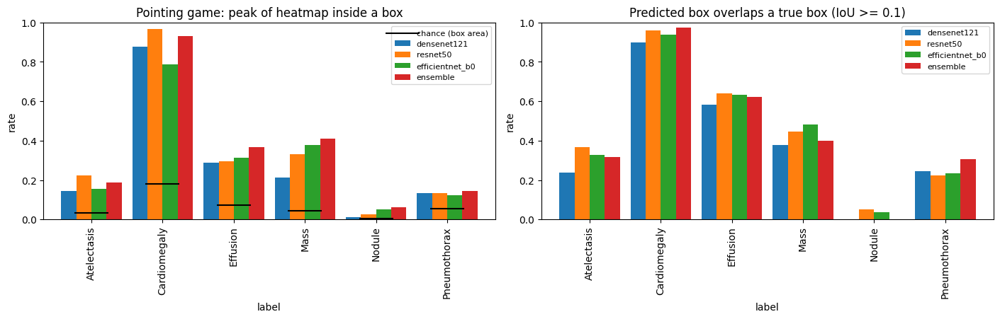

In [10]:
# [Cell E] Localization results (headline = images that were not in the training sample)
METRIC_COLS = ["pointing_hit", "energy_in_box", "iou", "hit_iou_0.1", "hit_iou_0.3", "hit_iou_0.5", "box_area_frac"]
MODEL_ORDER = BACKBONES + ["ensemble"]


def summarize(df, by):
    g = df.groupby(by)
    out = g[METRIC_COLS].mean()
    out.insert(0, "n_boxes", g.size())
    return out.round(3)


held_out = loc_df[~loc_df["seen_in_training"]]
n_held = int((held_out["model"] == "ensemble").sum())
n_all = int((loc_df["model"] == "ensemble").sum())
print(f"{n_held} of {n_all} image-finding pairs are on images not in the training sample (headline numbers)")

overall = summarize(held_out, "model").reindex(MODEL_ORDER)
print("\nOverall, held-out images. box_area_frac is the chance level for pointing_hit and energy_in_box.")
display(overall)
print("\nOnly where the model detected the finding (probability >= %.2f):" % DETECT_THRESH)
display(summarize(held_out[held_out["prob"] >= DETECT_THRESH], "model").reindex(MODEL_ORDER))
print("\nPer label, held-out images:")
per_label_loc = summarize(held_out, ["label", "model"])
display(per_label_loc)
print("\nAll boxed images, including those in the training sample (optimistic):")
display(summarize(loc_df, "model").reindex(MODEL_ORDER))

overall.to_csv(OUTPUT_DIR / "localization_overall_heldout.csv")
per_label_loc.to_csv(OUTPUT_DIR / "localization_per_label_heldout.csv")

labels_present = sorted(held_out["label"].unique())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), constrained_layout=True)
for ax, metric, title in zip(axes, ["pointing_hit", "hit_iou_0.1"],
                             ["Pointing game: peak of heatmap inside a box", "Predicted box overlaps a true box (IoU >= 0.1)"]):
    table = held_out.pivot_table(index="label", columns="model", values=metric, aggfunc="mean")
    table = table.reindex(labels_present)[MODEL_ORDER]
    table.plot.bar(ax=ax, width=0.85)
    if metric == "pointing_hit":
        chance = held_out[held_out["model"] == "ensemble"].groupby("label")["box_area_frac"].mean().reindex(labels_present)
        ax.scatter(range(len(labels_present)), chance.values, marker="_", s=1200, c="k", zorder=3, label="chance (box area)")
    ax.set_title(title)
    ax.set_ylabel("rate")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8)
fig.savefig(OUTPUT_DIR / "localization_by_label.png", dpi=180, bbox_inches="tight")
plt.show()

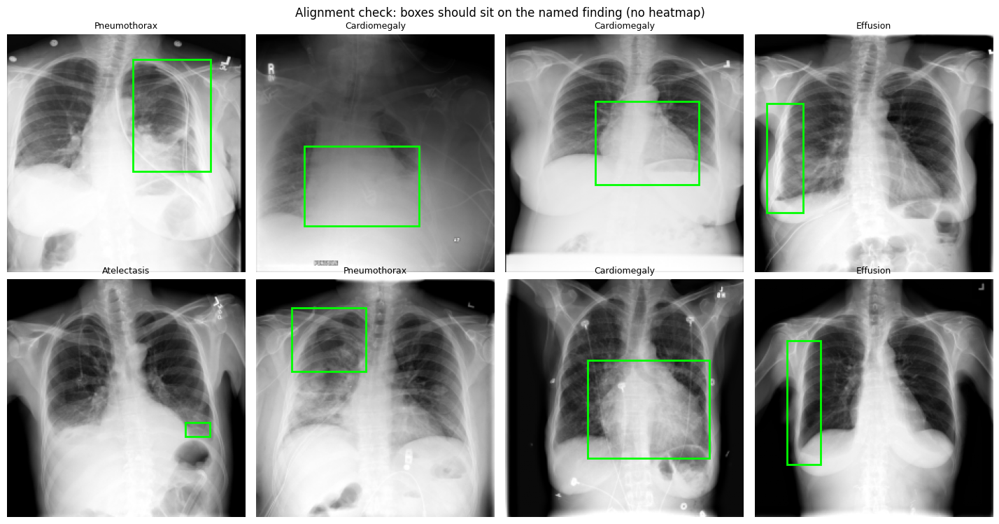

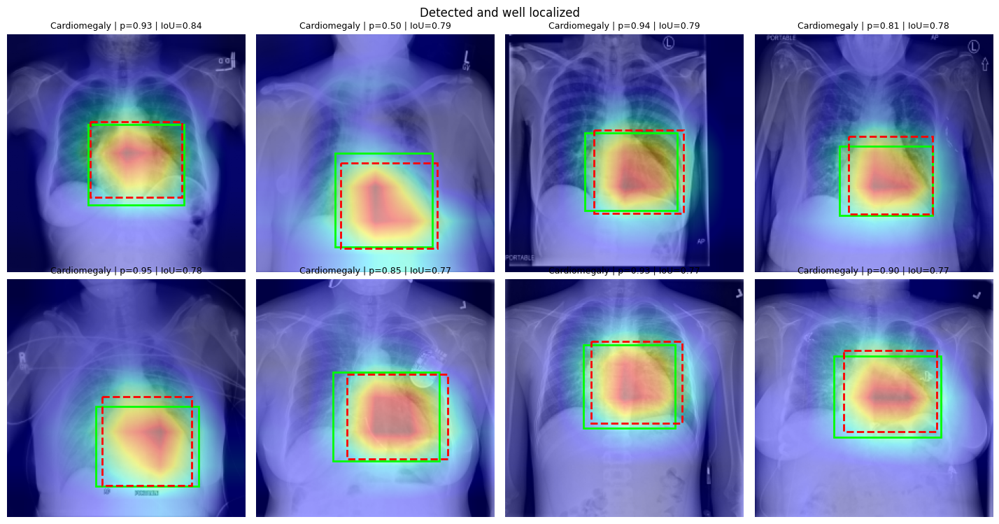

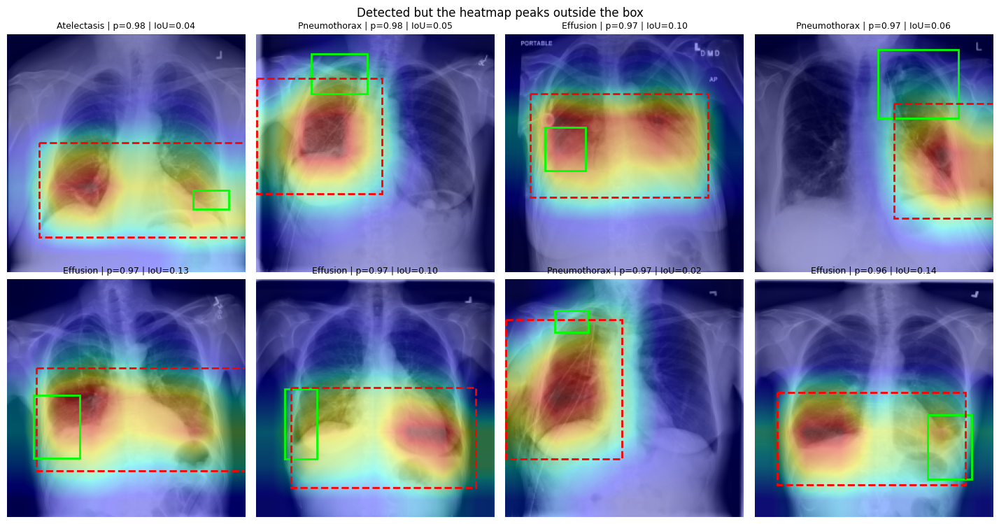

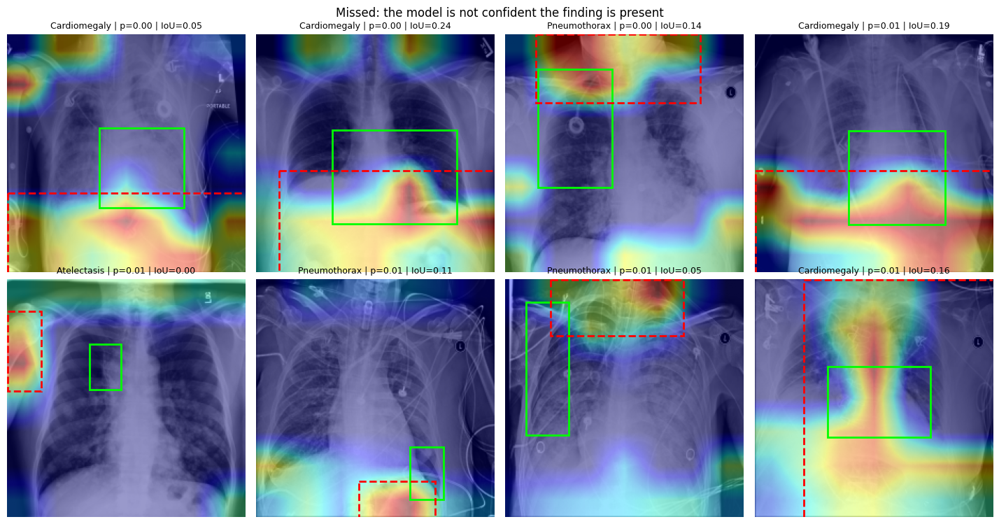

In [11]:
# [Cell F] Localization galleries: green = ground-truth box, red dashed = box from the heatmap
from matplotlib.patches import Rectangle

QUAL_MODEL = "ensemble"


def draw_case(ax, row, model_name, show_cam=True):
    img = box_dataset[image_pos[row["image"]]][0][0].numpy() * box_dataset.STD + box_dataset.MEAN
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    if show_cam:
        ax.imshow(cams[(model_name, row["image"], row["label"])].astype(np.float32),
                  cmap="jet", alpha=0.40, vmin=0, vmax=1)
    for x, y, w, h in gt_lookup[(row["image"], row["label"])]:
        ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="lime", linewidth=2))
    if show_cam and isinstance(row["pred_box"], tuple):
        x0, y0, x1, y1 = row["pred_box"]
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=2, linestyle="--"))
    ax.set_title(f"{row['label']} | p={row['prob']:.2f} | IoU={row['iou']:.2f}" if show_cam else row["label"], fontsize=9)
    ax.axis("off")


def gallery(df, model_name, title, fname, n=8, cols=4, show_cam=True):
    df = df.head(n)
    if df.empty:
        print("No cases for:", title)
        return
    n_rows = math.ceil(len(df) / cols)
    fig, axes = plt.subplots(n_rows, cols, figsize=(3.6 * cols, 3.8 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, row) in zip(axes, df.iterrows()):
        draw_case(ax, row, model_name, show_cam)
    for ax in axes[len(df):]:
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / fname, dpi=170, bbox_inches="tight")
    plt.show()


q = held_out[held_out["model"] == QUAL_MODEL]
gallery(q.sample(n=min(8, len(q)), random_state=SEED), QUAL_MODEL,
        "Alignment check: boxes should sit on the named finding (no heatmap)", "loc_alignment_check.png", show_cam=False)
gallery(q[q["prob"] >= DETECT_THRESH].sort_values("iou", ascending=False), QUAL_MODEL,
        "Detected and well localized", "loc_success.png")
gallery(q[(q["prob"] >= DETECT_THRESH) & (q["pointing_hit"] == 0)].sort_values("prob", ascending=False), QUAL_MODEL,
        "Detected but the heatmap peaks outside the box", "loc_failure_mislocalized.png")
gallery(q[q["prob"] < 0.3].sort_values("prob"), QUAL_MODEL,
        "Missed: the model is not confident the finding is present", "loc_failure_missed.png")

Ensemble method chosen on validation: mean_logit | best single backbone on test: densenet121


,test_macro_auroc,ci_2.5,ci_97.5
method,,,
densenet121,0.7938,0.7869,0.8002
resnet50,0.7934,0.7869,0.7997
efficientnet_b0,0.7909,0.7842,0.7962
mean_logit,0.8075,0.8007,0.8133


mean_logit minus densenet121: +0.0137 macro AUROC (paired patient bootstrap 95% CI +0.0115 to +0.0157)


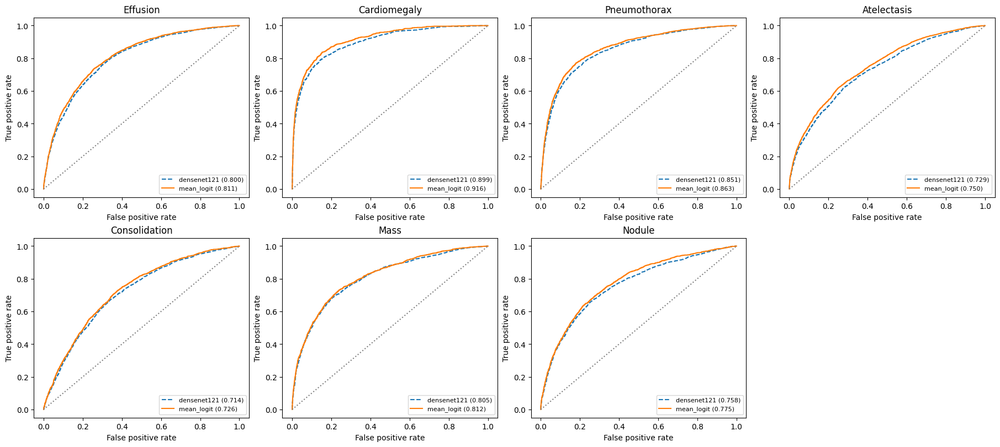

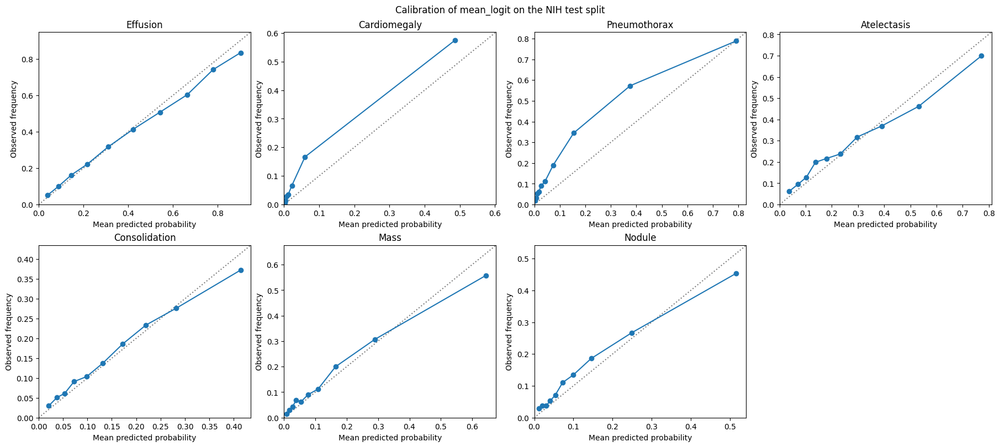

,label,prevalence,ECE
0,Effusion,0.3955,0.0259
1,Cardiomegaly,0.0908,0.0308
2,Pneumothorax,0.2263,0.0764
3,Atelectasis,0.2784,0.0364
4,Consolidation,0.1541,0.0135
5,Mass,0.1484,0.0228
6,Nodule,0.1378,0.0263


,label,CheXNet (published),densenet121,resnet50,efficientnet_b0,ensemble (mean_logit)
0,Effusion,0.8638,0.8001,0.7978,0.7973,0.8106
1,Cardiomegaly,0.9248,0.8989,0.9081,0.8999,0.9157
2,Pneumothorax,0.8887,0.8507,0.8441,0.8424,0.8632
3,Atelectasis,0.8094,0.7289,0.7407,0.7416,0.7497
4,Consolidation,0.7901,0.7143,0.7069,0.7105,0.7260
5,Mass,0.8676,0.8055,0.7925,0.7901,0.8122
6,Nodule,0.7802,0.7585,0.7640,0.7546,0.7751
7,macro (7 labels),0.8464,0.7938,0.7934,0.7909,0.8075


Labels more than 0.05 below the ensemble's mean per-label AUROC: Atelectasis (0.750), Consolidation (0.726)


In [12]:
# [Cell G] Classification results on the NIH test split (the ensemble method is chosen on validation only)
from sklearn.metrics import roc_curve

chosen_method = validation_comparison.iloc[0]["method"]
cal_method = chosen_method if chosen_method != "rank_mean" else "mean_probability"   # rank scores are not probabilities
best_single = max(BACKBONES, key=lambda b: macro_auroc_arr(test_scores[b], test_targets))
print("Ensemble method chosen on validation:", chosen_method, "| best single backbone on test:", best_single)

headline = bootstrap_df.set_index("method").loc[BACKBONES + [chosen_method]].round(4)
display(headline)
idx = {n: i for i, n in enumerate(bootstrap_names)}
diff = bootstrap_draws[:, idx[chosen_method]] - bootstrap_draws[:, idx[best_single]]
point = (macro_auroc_arr(test_scores[chosen_method], test_targets)
         - macro_auroc_arr(test_scores[best_single], test_targets))
lo, hi = np.nanpercentile(diff, [2.5, 97.5])
print(f"{chosen_method} minus {best_single}: {point:+.4f} macro AUROC (paired patient bootstrap 95% CI {lo:+.4f} to {hi:+.4f})")
headline.to_csv(OUTPUT_DIR / "headline_test_results.csv")

# ROC curves per label
fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
for j, (ax, label) in enumerate(zip(axes.ravel(), LABELS)):
    for name, style in [(best_single, "--"), (chosen_method, "-")]:
        fpr, tpr, _ = roc_curve(test_targets[:, j], test_scores[name][:, j])
        ax.plot(fpr, tpr, style, label=f"{name} ({roc_auc_score(test_targets[:, j], test_scores[name][:, j]):.3f})")
    ax.plot([0, 1], [0, 1], ":", color="gray")
    ax.set_title(label)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(fontsize=8, loc="lower right")
for ax in axes.ravel()[len(LABELS):]:
    ax.axis("off")
fig.savefig(OUTPUT_DIR / "test_roc_curves.png", dpi=170, bbox_inches="tight")
plt.show()


# Reliability diagrams (equal-count bins) and expected calibration error
def ece_quantile(y, p, bins=10):
    order = np.argsort(p)
    y, p = y[order], p[order]
    return float(sum(len(c) / len(p) * abs(y[c].mean() - p[c].mean())
                     for c in np.array_split(np.arange(len(p)), bins) if len(c)))


cal_scores = test_scores[cal_method]
fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
ece_rows = []
for j, (ax, label) in enumerate(zip(axes.ravel(), LABELS)):
    y, p = test_targets[:, j], cal_scores[:, j]
    chunks = np.array_split(np.argsort(p), 10)
    mean_p = [p[c].mean() for c in chunks]
    frac_pos = [y[c].mean() for c in chunks]
    lim = max(max(mean_p), max(frac_pos)) * 1.05
    ax.plot([0, lim], [0, lim], ":", color="gray")
    ax.plot(mean_p, frac_pos, marker="o")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_title(label)
    ax.set_xlabel("Mean predicted probability")
    ax.set_ylabel("Observed frequency")
    ece_rows.append({"label": label, "prevalence": float(y.mean()), "ECE": ece_quantile(y, p)})
for ax in axes.ravel()[len(LABELS):]:
    ax.axis("off")
fig.suptitle(f"Calibration of {cal_method} on the NIH test split")
fig.savefig(OUTPUT_DIR / "test_calibration.png", dpi=170, bbox_inches="tight")
plt.show()
ece_df = pd.DataFrame(ece_rows)
display(ece_df.round(4))
ece_df.to_csv(OUTPUT_DIR / "test_calibration_ece.csv", index=False)

# Per-label comparison with published CheXNet AUROCs (Rajpurkar et al. 2017).
# Indicative only: CheXNet used its own patient split of ChestX-ray14, not the official one used here.
CHEXNET_AUROC = {"Atelectasis": 0.8094, "Cardiomegaly": 0.9248, "Effusion": 0.8638, "Mass": 0.8676,
                 "Nodule": 0.7802, "Pneumothorax": 0.8887, "Consolidation": 0.7901}
tc = test_comparison.set_index("method")
bench = pd.DataFrame({"label": LABELS})
bench["CheXNet (published)"] = bench["label"].map(CHEXNET_AUROC)
for b in BACKBONES:
    bench[b] = [tc.loc[b, f"AUROC_{l}"] for l in LABELS]
bench[f"ensemble ({chosen_method})"] = [tc.loc[chosen_method, f"AUROC_{l}"] for l in LABELS]
bench.loc[len(bench)] = ["macro (7 labels)", *bench.iloc[:, 1:].mean().tolist()]
display(bench.round(4))
bench.to_csv(OUTPUT_DIR / "benchmark_comparison.csv", index=False)

per_label_ens = tc.loc[chosen_method, [f"AUROC_{l}" for l in LABELS]].astype(float)
weak = per_label_ens[per_label_ens < per_label_ens.mean() - 0.05]
print("Labels more than 0.05 below the ensemble's mean per-label AUROC:",
      ", ".join(f"{k.replace('AUROC_', '')} ({v:.3f})" for k, v in weak.items()) or "none")

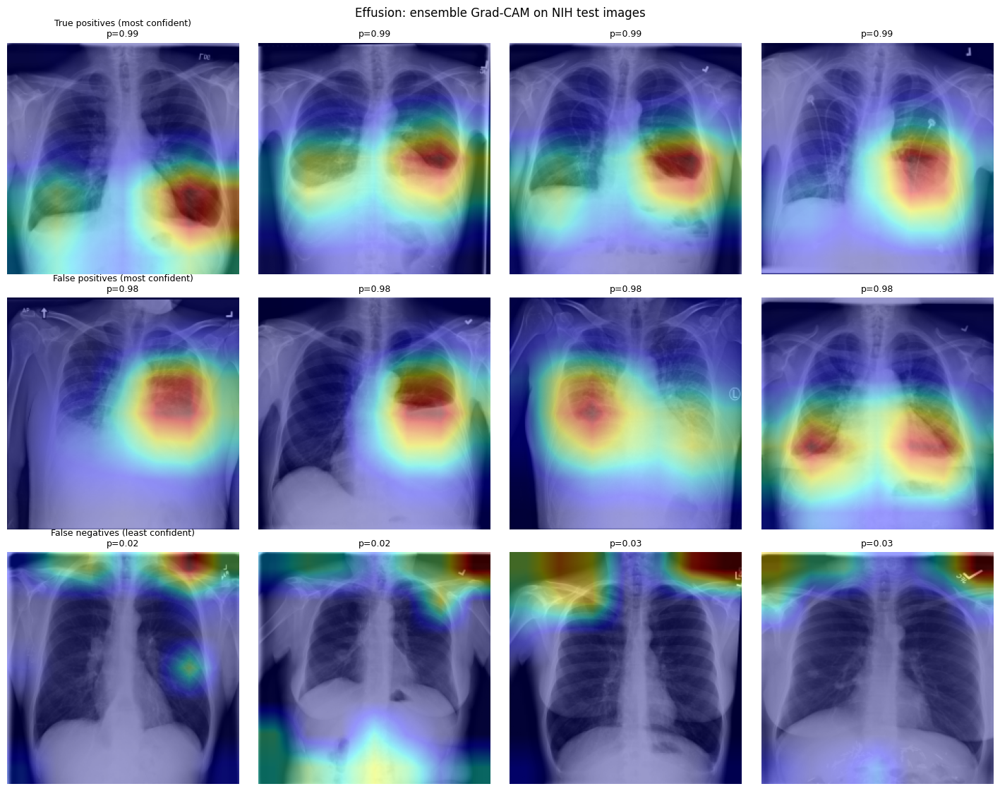

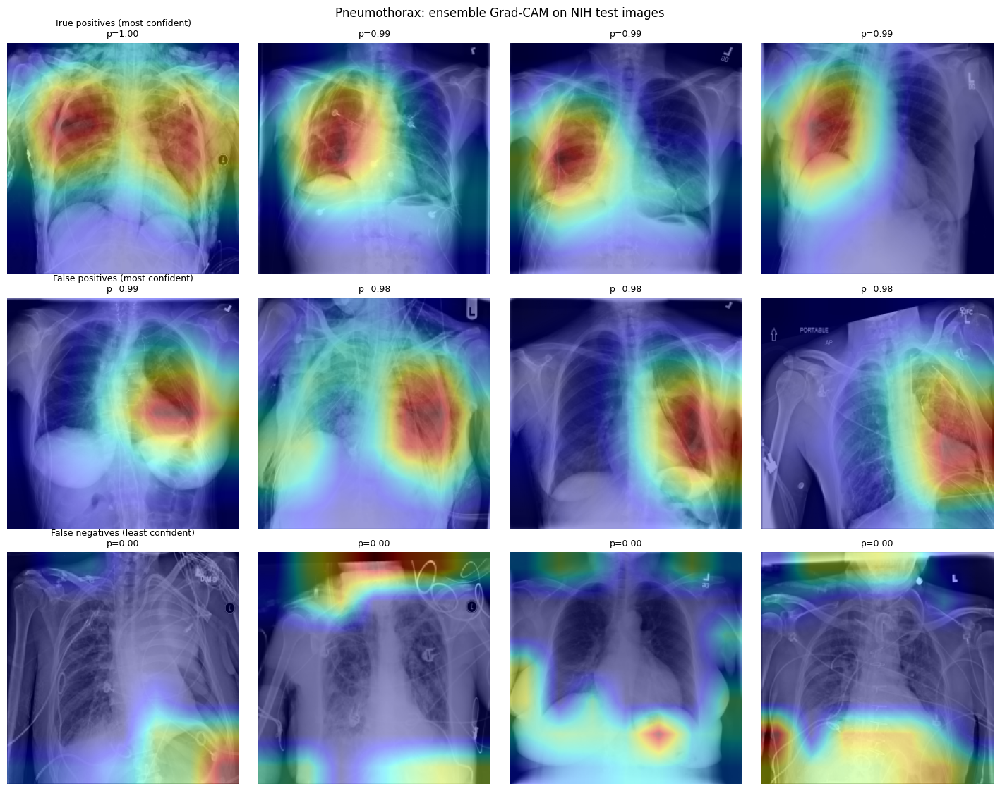

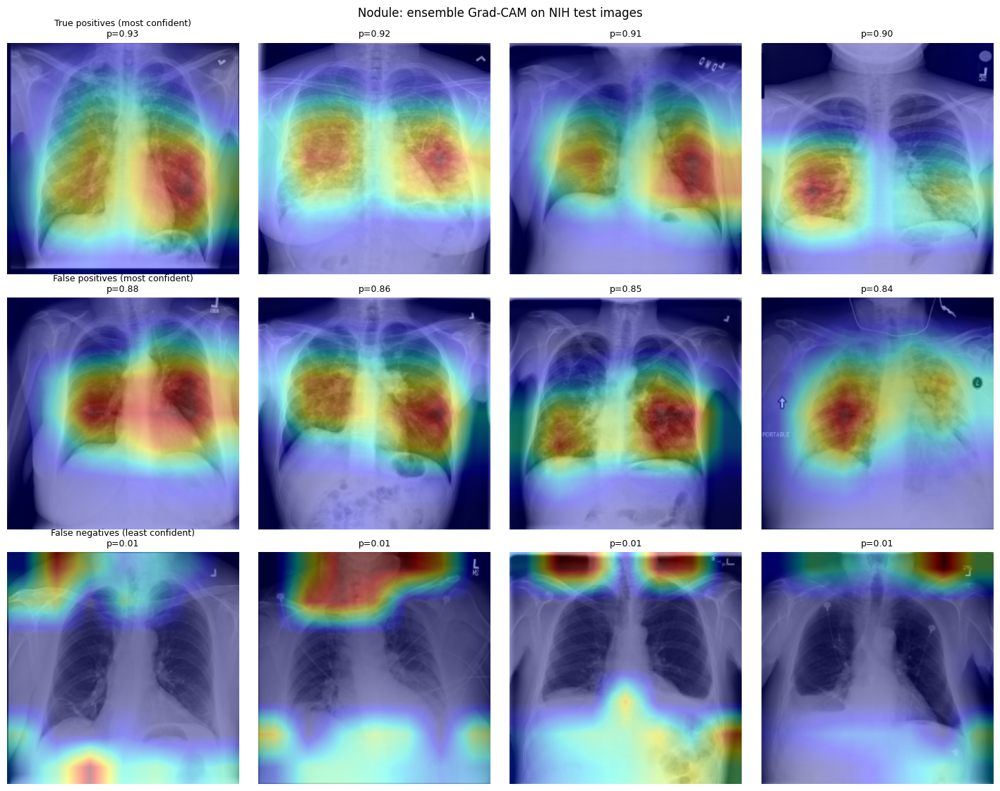

In [13]:
# [Cell H] Classification examples with Grad-CAM: confident hits, confident false alarms, missed findings
QUAL_LABELS = ["Effusion", "Pneumothorax", "Nodule"]
N_PER_GROUP = 4
test_dataset = NIHShardDataset(test_data, setup="A", training=False)


def show_classification_cases(label):
    j = LABELS.index(label)
    y, p = test_targets[:, j], test_scores[cal_method][:, j]
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    groups = {
        "True positives (most confident)": pos[np.argsort(-p[pos])][:N_PER_GROUP],
        "False positives (most confident)": neg[np.argsort(-p[neg])][:N_PER_GROUP],
        "False negatives (least confident)": pos[np.argsort(p[pos])][:N_PER_GROUP],
    }
    fig, axes = plt.subplots(len(groups), N_PER_GROUP, figsize=(3.6 * N_PER_GROUP, 3.8 * len(groups)))
    for r, (title, indices) in enumerate(groups.items()):
        for c in range(N_PER_GROUP):
            ax = axes[r, c]
            ax.axis("off")
            if c >= len(indices):
                continue
            i = int(indices[c])
            image = test_dataset[i][0]
            cam = ensemble_cam(image.unsqueeze(0).to(DEVICE), j)["ensemble"][0]
            ax.imshow(image[0].numpy() * test_dataset.STD + test_dataset.MEAN, cmap="gray", vmin=0, vmax=1)
            ax.imshow(cam, cmap="jet", alpha=0.40, vmin=0, vmax=1)
            ax.set_title(f"{title}\np={p[i]:.2f}" if c == 0 else f"p={p[i]:.2f}", fontsize=9)
    fig.suptitle(f"{label}: ensemble Grad-CAM on NIH test images")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"cls_cases_{label}.png", dpi=170, bbox_inches="tight")
    plt.show()


for label in QUAL_LABELS:
    show_classification_cases(label)

Best validation macro AUROC by setup:


backbone,densenet121,resnet50,efficientnet_b0
setup,,,
B,0.8177,0.8179,0.8164
C,0.8209,0.8208,0.8126
E,0.8214,0.8210,0.8162


Change relative to setup B (the baseline augmentation from tuning):


backbone,densenet121,resnet50,efficientnet_b0
setup,,,
B,0.0000,0.0000,0.0000
C,0.0031,0.0029,-0.0038
E,0.0036,0.0031,-0.0002


Validation minus clean-train loss at the best epoch (smaller = smaller generalization gap):


backbone,densenet121,resnet50,efficientnet_b0
setup,,,
B,0.0492,0.0727,0.0771
C,0.0972,0.0509,0.0600
E,0.0694,0.0619,0.0560


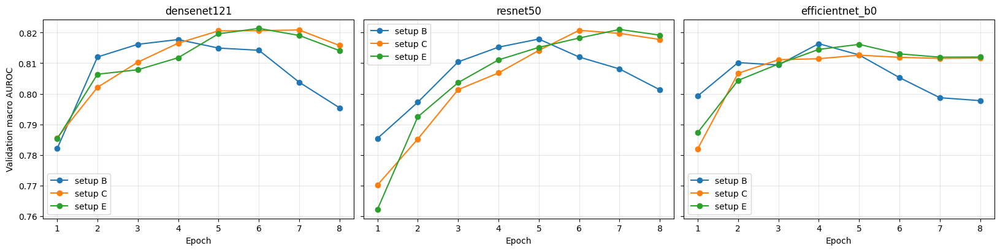

,backbone,setup,best_epoch,min_val_loss_epoch,epochs_run,final_loss_gap,max_val_loss_jump,mean_frac_clipped,min_loss_scale,observations
0,densenet121,B,4,4,8,0.2231,0.0196,0.4640,32768.0,val-loss spike of +0.020; final val-train loss gap +0.223; AUROC flat over the last 3 epochs
1,densenet121,C,7,5,8,0.1148,0.0097,0.2375,32768.0,val loss bottomed at epoch 5 but AUROC peaked at 7 (loss and ranking diverge); final val-train loss gap +0.115; AUROC flat over the last 3 epochs
2,densenet121,E,6,5,8,0.1097,0.0075,0.2045,32768.0,final val-train loss gap +0.110; AUROC flat over the last 3 epochs
3,efficientnet_b0,B,4,4,8,0.2435,0.0245,0.1028,65536.0,val-loss spike of +0.025; final val-train loss gap +0.243; AUROC flat over the last 3 epochs
4,efficientnet_b0,C,5,4,8,0.1075,0.0055,0.0140,65536.0,final val-train loss gap +0.108; AUROC flat over the last 3 epochs
5,efficientnet_b0,E,5,4,8,0.1107,0.0053,0.0097,65536.0,final val-train loss gap +0.111; AUROC flat over the last 3 epochs
6,resnet50,B,5,3,8,0.2224,0.0211,0.3422,65536.0,val loss bottomed at epoch 3 but AUROC peaked at 5 (loss and ranking diverge); val-loss spike of +0.021; final val-train loss gap +0.222; AUROC flat over the last 3 epochs
7,resnet50,C,6,7,8,0.0828,0.0045,0.0716,65536.0,final val-train loss gap +0.083
8,resnet50,E,7,7,8,0.0755,0.0049,0.0552,65536.0,final val-train loss gap +0.075


In [14]:
# [Cell I] Setup comparison and training dynamics, read from the saved generalization outputs
logs = pd.read_csv(GEN_ROOT / "combined_training_logs.csv")
best_epoch_df = pd.read_csv(GEN_ROOT / "best_epoch_comparison.csv")

val_pivot = best_epoch_df.pivot(index="setup", columns="backbone", values="val_macro_auroc")[BACKBONES]
print("Best validation macro AUROC by setup:")
display(val_pivot.round(4))
if "B" in val_pivot.index:
    print("Change relative to setup B (the baseline augmentation from tuning):")
    display((val_pivot - val_pivot.loc["B"]).round(4))
print("Validation minus clean-train loss at the best epoch (smaller = smaller generalization gap):")
display(best_epoch_df.pivot(index="setup", columns="backbone", values="loss_gap")[BACKBONES].round(4))
val_pivot.to_csv(OUTPUT_DIR / "setup_comparison_val_auroc.csv")

# Convergence of the primary validation metric
fig, axes = plt.subplots(1, len(BACKBONES), figsize=(5.4 * len(BACKBONES), 4), sharey=True, constrained_layout=True)
for ax, b in zip(np.atleast_1d(axes), BACKBONES):
    for s in sorted(logs["setup"].unique()):
        h = logs[(logs["backbone"] == b) & (logs["setup"] == s)].sort_values("epoch")
        ax.plot(h["epoch"], h["val_macro_auroc"], marker="o", label=f"setup {s}")
    ax.set_title(b)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
np.atleast_1d(axes)[0].set_ylabel("Validation macro AUROC")
fig.savefig(OUTPUT_DIR / "convergence_val_auroc.png", dpi=170, bbox_inches="tight")
plt.show()


def run_observations(h, spike_tol=0.01, gap_tol=0.02, plateau_tol=0.001):
    """Flags are rules of thumb; adjust the tolerances to taste."""
    h = h.sort_values("epoch").reset_index(drop=True)
    last = h.iloc[-1]
    best_ep = int(h.loc[h["val_macro_auroc"].idxmax(), "epoch"])
    min_loss_ep = int(h.loc[h["val_loss"].idxmin(), "epoch"])
    max_jump = h["val_loss"].diff().max()
    notes = []
    if best_ep == int(last["epoch"]):
        notes.append("AUROC still rising at the last epoch (possibly under-trained)")
    if best_ep - min_loss_ep >= 2:
        notes.append(f"val loss bottomed at epoch {min_loss_ep} but AUROC peaked at {best_ep} (loss and ranking diverge)")
    if np.isfinite(max_jump) and max_jump > spike_tol:
        notes.append(f"val-loss spike of +{max_jump:.3f}")
    if last["loss_gap"] > gap_tol:
        notes.append(f"final val-train loss gap {last['loss_gap']:+.3f}")
    if len(h) >= 4 and h["val_macro_auroc"].iloc[-1] - h["val_macro_auroc"].iloc[-4] < plateau_tol:
        notes.append("AUROC flat over the last 3 epochs")
    if h["frac_clipped"].mean() > 0.5:
        notes.append("gradient clipping active on over half of the steps")
    if h["loss_scale"].min() < h["loss_scale"].iloc[0] / 16:
        notes.append("AMP loss scale dropped sharply (fp16 overflow)")
    return {"best_epoch": best_ep, "min_val_loss_epoch": min_loss_ep, "epochs_run": int(last["epoch"]),
            "final_loss_gap": float(last["loss_gap"]),
            "max_val_loss_jump": float(max_jump) if np.isfinite(max_jump) else np.nan,
            "mean_frac_clipped": float(h["frac_clipped"].mean()), "min_loss_scale": float(h["loss_scale"].min()),
            "observations": "; ".join(notes) or "nothing flagged"}


dynamics_df = pd.DataFrame([
    {"backbone": b, "setup": s, **run_observations(g)}
    for (b, s), g in logs.groupby(["backbone", "setup"])
])
pd.set_option("display.max_colwidth", 200)
display(dynamics_df.round(4))
dynamics_df.to_csv(OUTPUT_DIR / "training_dynamics_observations.csv", index=False)

In [15]:
# [Cell J] Optional: every saved checkpoint on the NIH test split (reported only, never used for selection)
RUN_TEST_ALL_SETUPS = True

if RUN_TEST_ALL_SETUPS:
    rows = []
    for b in BACKBONES:
        for s in sorted(logs["setup"].unique()):
            path = GEN_ROOT / b / s / "best_checkpoint.pt"
            if not path.is_file():
                continue
            model, _ = load_checkpoint_model(path)
            test_logits_s, y_s = collect_logits(model, test_loader_ensemble)
            rows.append({"backbone": b, "setup": s,
                         "test_macro_auroc": macro_auroc_arr(sigmoid_np(test_logits_s), y_s)})
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    setup_test = pd.DataFrame(rows).pivot(index="setup", columns="backbone", values="test_macro_auroc")[BACKBONES]
    display(setup_test.round(4))
    setup_test.to_csv(OUTPUT_DIR / "setup_comparison_test_auroc.csv")

backbone,densenet121,resnet50,efficientnet_b0
setup,,,
B,0.7936,0.7869,0.7909
C,0.7895,0.7892,0.7891
E,0.7938,0.7934,0.7912


In [16]:
# [Cell K] Save a summary and zip everything
import shutil

summary = {
    "dataset": "NIH ChestX-ray14 (official test split)",
    "selected_checkpoints": selected_checkpoint_info,
    "ensemble_method_chosen_on_validation": chosen_method,
    "test_macro_auroc": {name: float(macro_auroc_arr(test_scores[name], test_targets))
                         for name in BACKBONES + [chosen_method]},
    "localization_heldout": overall.reset_index().to_dict("records"),
    "localization_settings": {"cam_threshold_fraction": CAM_FRAC, "iou_hits": list(IOU_HITS), "detect_threshold": DETECT_THRESH},
}
(OUTPUT_DIR / "final_evaluation_summary.json").write_text(
    json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
archive = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR.parent, base_dir=OUTPUT_DIR.name)
print("Saved", archive)
for p in sorted(OUTPUT_DIR.iterdir()):
    print("-", p.name)

Saved /kaggle/working/nih_final_evaluation.zip
- benchmark_comparison.csv
- cls_cases_Effusion.png
- cls_cases_Nodule.png
- cls_cases_Pneumothorax.png
- convergence_val_auroc.png
- ensemble_validation_oof_comparison.csv
- final_evaluation_summary.json
- headline_test_results.csv
- loc_alignment_check.png
- loc_failure_mislocalized.png
- loc_failure_missed.png
- loc_success.png
- localization_by_label.png
- localization_overall_heldout.csv
- localization_per_box.csv
- localization_per_label_heldout.csv
- nih_ensemble_manifest.json
- nih_ensemble_predictions.npz
- nih_test_backbone_rank_correlation.csv
- nih_test_ensemble_method_comparison.csv
- nih_test_ensemble_patient_bootstrap.csv
- setup_comparison_test_auroc.csv
- setup_comparison_val_auroc.csv
- stacking_all_features_fit_info.json
- stacking_per_label_fit_info.json
- test_calibration.png
- test_calibration_ece.csv
- test_roc_curves.png
- training_dynamics_observations.csv
- weighted_logit_global_fit_info.json
- weighted_logit_per_